In [2]:
import os
import pandas as pd
import kaggle

# משיכת נתוני הטיטאניק ישירות מקאגל ויצירת תיקיית data אוטומטית
os.makedirs('data', exist_ok=True)
kaggle.api.competition_download_files('titanic', path='./data', unzip=True)

# טעינת הנתונים ל-Pandas DataFrames
train_df = pd.read_csv('data/train.csv')
test_df = pd.read_csv('data/test.csv')

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
train_df.head()

Train shape: (891, 12)
Test shape: (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
# בדיקת ערכים חסרים בדאטה-סט של האימון
print("Missing values in Train Data:")
print(train_df.isnull().sum())

Missing values in Train Data:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


**Conclusion.** Age is missing for 177 passengers, Cabin for 687, and Embarked for 2. Cabin is too sparse to use, so it stays out of the model.

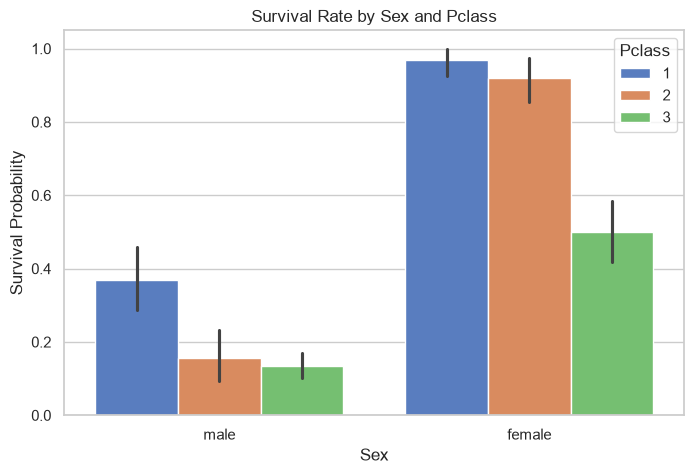

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# הגדרת סגנון לגרפים
sns.set(style="whitegrid")

# יצירת גרף שמשווה הישרדות לפי מין ומחלקה (Pclass)
plt.figure(figsize=(8, 5))
sns.barplot(x="Sex", y="Survived", hue="Pclass", data=train_df, palette="muted")
plt.title("Survival Rate by Sex and Pclass")
plt.ylabel("Survival Probability")
plt.show()

**Conclusion.** Women and 1st-class passengers survive more often. These are the strongest signals, so both `Sex` and `Pclass` go into the model.

Survival distribution:
Survived
0    0.616
1    0.384
Name: proportion, dtype: float64

       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.486592    0.836071   14.526497    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000    0.000000    2.000000   20.125000    0.000000   
50%     446.000000    0.000000    3.000000   28.000000    0.000000   
75%     668.500000    1.000000    3.000000   38.000000    1.000000   
max     891.000000    1.000000    3.000000   80.000000    8.000000   

            Parch        Fare  
count  891.000000  891.000000  
mean     0.381594   32.204208  
std      0.806057   49.693429  
min      0.000000    0.000000  
25%      0.000000    7.910400  
50%      0.000000   14.454200  
75%      0.000000   31.000000  
max      6.000000  512.32

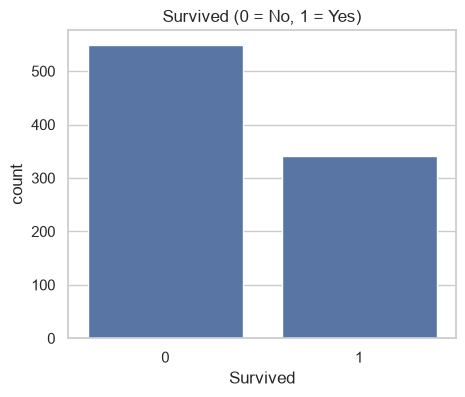

In [5]:
# התפלגות משתנה המטרה וסטטיסטיקה תיאורית
print("Survival distribution:")
print(train_df['Survived'].value_counts(normalize=True).round(3))
print()
print(train_df.describe())

plt.figure(figsize=(5, 4))
sns.countplot(x="Survived", data=train_df)
plt.title("Survived (0 = No, 1 = Yes)")
plt.show()

**Conclusion.** About 38% of passengers survived. This class imbalance is later handled with a positive weight on the loss.

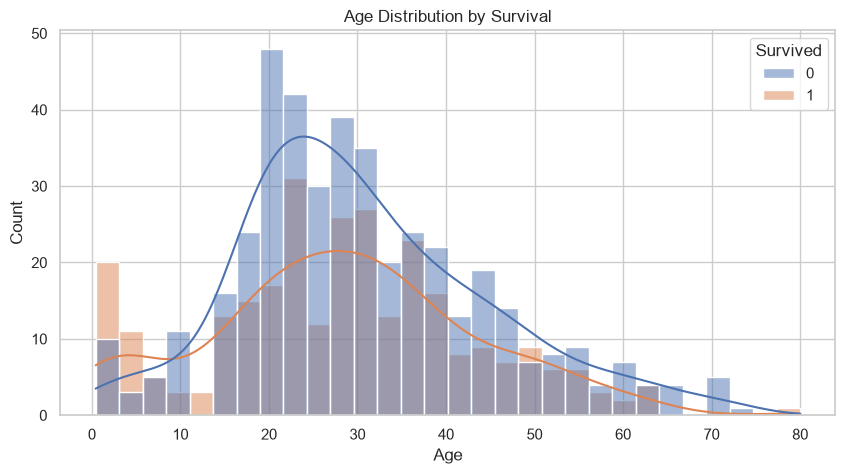

In [6]:
# התפלגות הגילאים לפי הישרדות
plt.figure(figsize=(10, 5))
sns.histplot(data=train_df, x="Age", hue="Survived", bins=30, kde=True, multiple="layer")
plt.title("Age Distribution by Survival")
plt.show()

**Conclusion.** Children survive more often, but age is missing for many passengers. Filling the median is not enough on its own, so training extracts `Title` from the name.

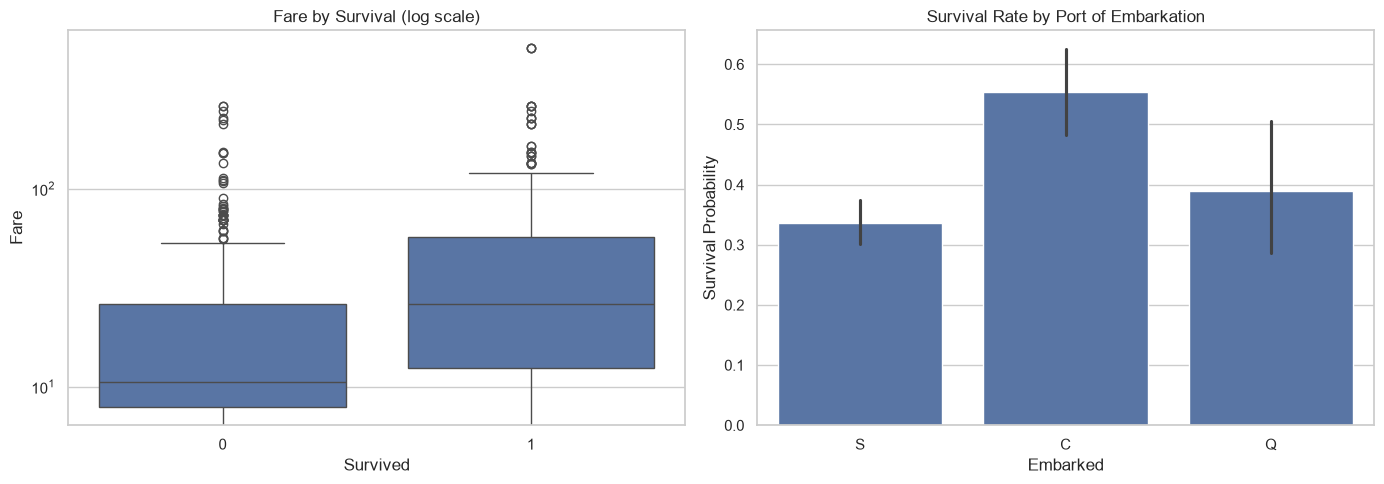

In [7]:
# מחיר כרטיס (Fare) ונמל עלייה (Embarked) מול הישרדות
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(x="Survived", y="Fare", data=train_df, ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("Fare by Survival (log scale)")

sns.barplot(x="Embarked", y="Survived", data=train_df, ax=axes[1])
axes[1].set_title("Survival Rate by Port of Embarkation")
axes[1].set_ylabel("Survival Probability")

plt.tight_layout()
plt.show()

**Conclusion.** A higher fare is associated with survival, and passengers who embarked at Cherbourg survive more often than those who embarked at Southampton.

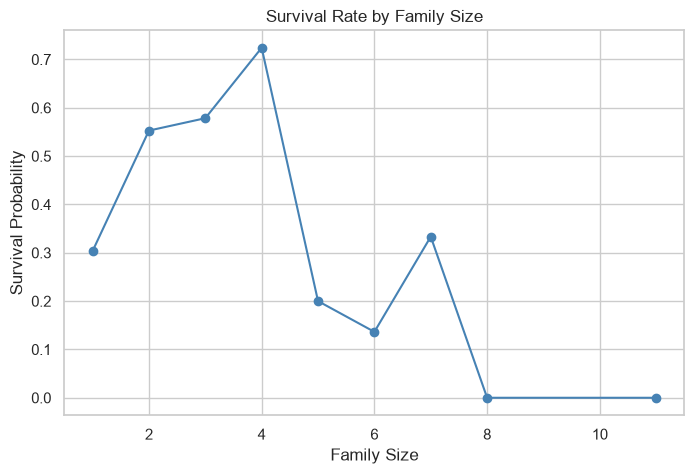

In [8]:
# הישרדות לפי גודל משפחה על הסיפון (SibSp + Parch + הנוסע עצמו)
family_size = train_df['SibSp'] + train_df['Parch'] + 1

plt.figure(figsize=(8, 5))
train_df.groupby(family_size)['Survived'].mean().plot(marker="o", color="steelblue")
plt.title("Survival Rate by Family Size")
plt.xlabel("Family Size")
plt.ylabel("Survival Probability")
plt.show()

**Conclusion.** Families of size 2–4 survive more often than passengers traveling alone or in large families. That is why `FamilySize` is a feature in `train.py`.

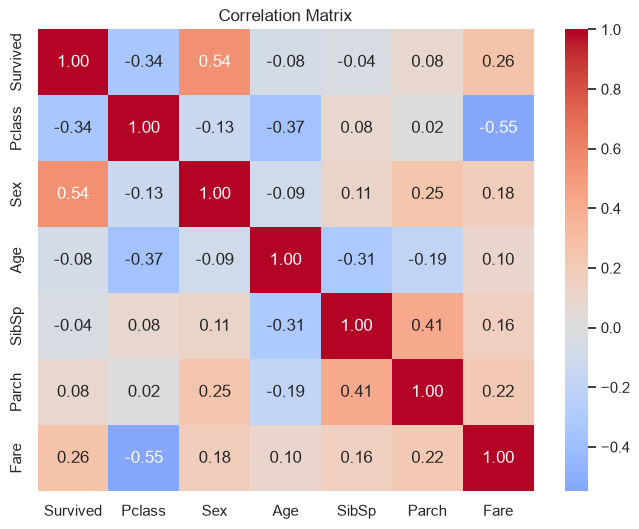

In [11]:
# מפת קורלציות בין התכונות המספריות לבין ההישרדות
eda_df = train_df.copy()
eda_df['Sex'] = eda_df['Sex'].map({'male': 0, 'female': 1})
num_cols = ['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare']

plt.figure(figsize=(8, 6))
sns.heatmap(eda_df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
plt.show()

**Conclusion.** Sex has the strongest correlation with survival, followed by Pclass (negative) and Fare.